In [92]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import torch




In [135]:
def get_density(x, k=50):
    """
    Computes the average k-NN distance in the input space as a proxy for inverse density.
    """
    if isinstance(x, np.ndarray):
        x = torch.FloatTensor(x)


    batch_size = x.shape[0]
    k = min(k, batch_size - 1)

    # We might need to do this in batches if x is very large
    if batch_size > 2000:
        avg_dists = []
        for i in range(0, batch_size, 1000):
            batch_x = x[i:i+1000]
            # Compute distances from batch to all points
            dists = torch.cdist(batch_x, x)
            knn_dist, _ = torch.topk(dists, k + 1, largest=False)
            avg_dists.append(knn_dist[:, 1:].mean(dim=1))
        return torch.cat(avg_dists, dim=0)
    else:
        x_dist = torch.cdist(x, x)
        x_knn_dist, _ = torch.topk(x_dist, k + 1, largest=False)
        return x_knn_dist[:, 1:].mean(dim=1)

In [136]:
def get_msd(x):
    z = (x-np.mean(x,axis = 1,keepdims=True))/np.std(x,axis = 1,keepdims=True)
    g = np.mean(np.abs(np.diff(z, axis = 1)),axis = 1)
    return g

In [306]:
import torch

def generate_constant_nonlinear_embedding(n_conditions: int, n_neurons: int) -> torch.Tensor:
    """
    Generates a nonlinear embedding of a 1D space into a high-dimensional neuron space
    where the trajectory is identical (constant) across all neurons.

    Args:
        n_conditions (int): Number of points in the low-dimensional space (-1 to 1).
        n_neurons (int): Target dimensionality (number of neurons).

    Returns:
        torch.Tensor: Shape (n_conditions, n_neurons) with identical columns and a mean of 1.0.
    """
    # 1. Create the base linear space of shape (n_conditions,)
    x = torch.linspace(-1, 1, n_conditions)

    # 2. Apply a fixed non-linear function (e.g., x^3 + sin(3x))
    # This creates a single trajectory for the conditions
    nonlinear_trajectory = (x ** 3) + torch.sin(3.0 * x)

    # 3. Enforce that the mean of this trajectory is exactly 1.0
    current_mean = nonlinear_trajectory.mean()
    normalized_trajectory = (nonlinear_trajectory - current_mean) + 1.0

    # 4. Reshape to (n_conditions, 1) and expand across the n_neurons dimension
    # .expand() creates a view without copying the underlying data in memory
    final_embedding = normalized_trajectory.unsqueeze(1).expand(n_conditions, n_neurons)

    # Optional: Use .clone() if you plan to modify individual neuron values later
    return final_embedding.clone()

# Example Usage:
# embedding = generate_constant_nonlinear_embedding(n_conditions=100, n_neurons=50)


In [307]:
# PyTorch Implementation of Sparse Balanced Network

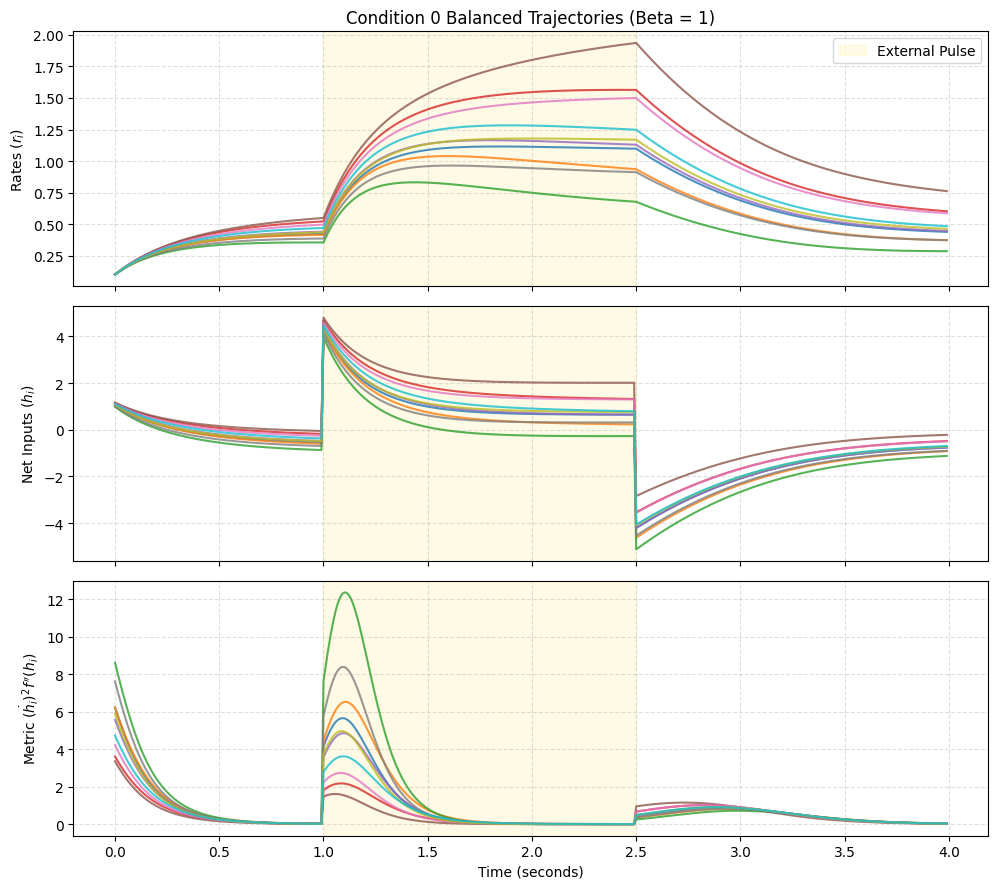

In [475]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

class SparseBalancedNetwork(nn.Module):
    def __init__(self, N, K, beta=1.0, dist_type='uniform', dist_mean=1.0, dist_std=0.5, p_e=0.8, g=4.5):
        """
        Differentiable Sparse Balanced Recurrent Neural Network Module.

        Activation function: f(h) = (1/beta) * ln(1 + e^(beta * h))
        """
        super().__init__()
        self.N = N
        self.K = K
        self.N_e = int(N * p_e)
        self.N_i = N - self.N_e
        self.beta = beta

        # 1. Calculate connection probability p and balance scale factor 1/sqrt(K)
        p_conn = K / N
        if p_conn > 1.0:
            raise ValueError(f"Requested K ({K}) cannot be greater than network size N ({N}).")

        scale = 1.0 / (K ** 0.5)
        target_w_e = dist_mean * scale
        target_w_i = -g * dist_mean * scale

        # 2. Draw raw weights from the selected distribution profile
        if dist_type == 'uniform':
            width = dist_std * (12.0 ** 0.5)
            low, high = dist_mean - width/2, dist_mean + width/2
            raw_E = torch.rand(N, self.N_e) * (high - low) + low
            raw_I = torch.rand(N, self.N_i) * (high - low) + low

        elif dist_type == 'gaussian':
            raw_E = torch.normal(mean=dist_mean, std=dist_std, size=(N, self.N_e))
            raw_I = torch.normal(mean=dist_mean, std=dist_std, size=(N, self.N_i))

        elif dist_type == 'lognormal':
            raw_E = torch.empty(N, self.N_e).log_normal_(mean=0.0, std=dist_std)
            raw_I = torch.empty(N, self.N_i).log_normal_(mean=0.0, std=dist_std)
        else:
            raise ValueError(f"Unknown distribution type: {dist_type}")

        # 3. Enforce Dale's Law cleanly using absolute values and normalize means

        W_E_init = torch.abs(raw_E) * (target_w_e / torch.mean(torch.abs(raw_E)))
        W_I_init = -abs(target_w_i) * torch.abs(raw_I) / torch.mean(torch.abs(raw_I))
        W_dense = torch.cat([W_E_init, W_I_init], dim=1)

        # 4. Generate the random sparsity masks based on the connection probability p
        mask = torch.rand(N, N) < p_conn

        # 5. Save variables and register buffers
        self.W_raw = nn.Parameter(W_dense)
        self.register_buffer('connectivity_mask', mask)
        self.register_buffer('I_bias', 1.5*torch.ones(1, N))

    @property
    def W(self):
        """Returns the effective sparse weight matrix dynamically enforcing the mask."""
        return self.W_raw * self.connectivity_mask

    def softplus(self, x):
        """f(x) = (1/beta) * ln(1 + e^(beta * x)) activation function."""
        bx = self.beta * x
        return (1.0 / self.beta) * torch.log(1.0 + torch.exp(torch.clamp(bx, min=-20, max=20)))

    def softplus_pprime(self, x):
        """Second derivative with respect to h: f''(x) = beta * e^(beta * x) / (1 + e^(beta * x))^2."""
        bx = self.beta * x
        ex = torch.exp(torch.clamp(bx, min=-20, max=20))
        return self.beta * ex / ((1.0 + ex) ** 2)

    def forward(self, I_conditions, stim_on, stim_off, dt, n_steps):
        """
        Forward simulation roll-out.
        Inputs shape: (n_condition, N)
        """
        n_condition, _ = I_conditions.shape
        r = torch.ones(n_condition, self.N, device=I_conditions.device) * 0.1

        R_all = torch.zeros(n_condition, self.N, n_steps, device=I_conditions.device)
        H_all = torch.zeros(n_condition, self.N, n_steps, device=I_conditions.device)
        Metric_all = torch.zeros(n_condition, self.N, n_steps, device=I_conditions.device)

        effective_W = self.W

        for k in range(n_steps):
            if stim_on <= k < stim_off:
                I_ext = I_conditions
            else:
                I_ext = 0.0

            # 1. Compute h_i using the masked sparse matrix
            h = torch.matmul(r, effective_W.T) + self.I_bias + I_ext

            # 2. Compute dot_r = -r + f(h)
            dot_r = -r + self.softplus(h)

            # 3. Compute dot_h = Sum(W_ij * dot_r_j)
            dot_h = torch.matmul(dot_r, effective_W.T)

            # 4. Compute second derivative f''(h)
            f_pprime = self.softplus_pprime(h)

            # 5. Compute metric: (dot_h_i)^2 * f''(h_i)
            metric = (dot_h ** 2) * f_pprime

            R_all[:, :, k] = r
            H_all[:, :, k] = h
            Metric_all[:, :, k] = metric

            r = r + dt * dot_r

        return R_all.permute(0,2,1), H_all.permute(0,2,1), Metric_all.permute(0,2,1)

# =====================================================================
# Execution & Visualization Block
# =====================================================================
if __name__ == "__main__":
    # Define hyper-parameters
    N_neurons = 2000
    K_degree = 2000      # 20% sparsity (400/2000)
    beta_gain = 1     # Scaled softplus multiplier
    n_conds = 2         # Simulating 2 different experimental conditions
    steps = 400
    dt_val = 0.01

    # Instantiate the sparse network module
    model = SparseBalancedNetwork(
        N=N_neurons,
        K=K_degree,
        beta=beta_gain,
        dist_type='gaussian',
        dist_mean=1.0,
        dist_std=0.3,
        g = 4.5
    )

    # Generate unique step-input profiles for each condition
    # inputs = torch.zeros(n_conds, N_neurons)
    # inputs[0, :] = 2  # Condition 0: Uniform intermediate input drive
    # inputs[1, :] = 5 # Condition 1: High input drive

    inputs =  5+1*generate_constant_nonlinear_embedding(n_conditions=n_conds, n_neurons=N_neurons)
    # Run the rollout simulation
    # Stimulus runs from step index 100 to 250
    R, H, M = model(I_conditions=inputs, stim_on=100, stim_off=250, dt=dt_val, n_steps=steps)

    # Convert vectors to time coordinates for plotting
    t_axis = [i * dt_val for i in range(steps)]

    # Build a 3-panel display tracking Condition 0 for the first 10 neurons
    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
    condition_idx = 0  # Isolate Condition 0

    # Transpose matrix slices (.T) to align correctly with the 1D time vector
    axes[0].plot(t_axis, R[condition_idx, :, :10].detach().numpy(), alpha=0.8)
    axes[0].axvspan(100*dt_val, 250*dt_val, color='gold', alpha=0.1, label='External Pulse')
    axes[0].set_ylabel(r"Rates ($r_i$)")
    axes[0].set_title(f"Condition {condition_idx} Balanced Trajectories (Beta = {beta_gain})")
    axes[0].grid(True, linestyle='--', alpha=0.4)
    axes[0].legend(loc='upper right')

    axes[1].plot(t_axis, H[condition_idx, :, :10].detach().numpy(), alpha=0.8)
    axes[1].axvspan(100*dt_val, 250*dt_val, color='gold', alpha=0.1)
    axes[1].set_ylabel(r"Net Inputs ($h_i$)")
    axes[1].grid(True, linestyle='--', alpha=0.4)

    axes[2].plot(t_axis, M[condition_idx, :, :10].detach().numpy(), alpha=0.8)
    axes[2].axvspan(100*dt_val, 250*dt_val, color='gold', alpha=0.1)
    axes[2].set_ylabel(r"Metric $(\dot{h}_i)^2 f^{\prime\prime}(h_i)$")
    axes[2].set_xlabel("Time (seconds)")
    axes[2].grid(True, linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()


Text(-0.05, 1, 'c')

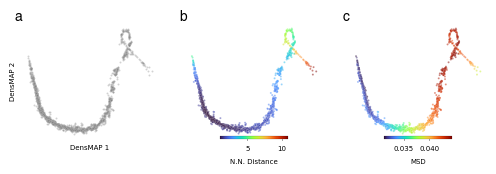

In [476]:
from sklearn.model_selection import KFold
from tqdm.auto import tqdm
import os
import sys
import seaborn as sns
import umap
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

y = R.detach().numpy()[:,100:250,:]
g = get_msd(y.reshape(-1,y.shape[2]).T)

y = (y-np.mean(y,axis = (0,1),keepdims=True))/np.std(y,axis = (0,1),keepdims=True)
y = y.reshape(-1,y.shape[2]).T
# g = np.mean(np.abs(np.diff(y, axis = 1)),axis = 1)



z_neurons = umap.UMAP(densmap=True,dens_lambda=1,n_neighbors=1000).fit_transform(y)
loc_density = get_density(y, k=500).numpy()




fig = plt.figure(figsize=(6, 1.5))
gs = gridspec.GridSpec(1, 3)
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])
ax3 = plt.subplot(gs[2])


# Gray
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], color='gray', s=2, alpha=.35,ax=ax1)

# NN Distance
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=loc_density,cmap  = 'turbo', s=2, alpha=.5,ax=ax2)
cax = inset_axes(
        ax2, width="50%", height="2%",
        loc="lower center", borderpad=0
    )

norm = plt.Normalize(loc_density.min(), loc_density.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

# MSD

sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=g,cmap='turbo', s=2, alpha=.5,ax=ax3)
cax = inset_axes(
        ax3, width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(g.min(), g.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("MSD", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)





# 4. Global figure customizations
#fig.suptitle("Main Title for All 5 Subplots", fontsize=18, fontweight="bold", y=1.05)

# Automatically adjusts subplot parameters so that the labels don't overlap
for ax in [ax1,ax2,ax3]:
    for spine in ax.spines.values():
        spine.set_visible(False)

    # 2. Hide the tick marks and tick numbers
    ax.set_xticks([])
    ax.set_yticks([])

    # 3. Add your labels normally
    ax.set_xlabel('')
    ax.set_ylabel('')



ax1.set_xlabel('DensMAP 1',fontsize = 5)
ax1.set_ylabel('DensMAP 2',fontsize = 5)



#fig.subplots_adjust(wspace=0.2)

# Figure labels
ax1.text(-0.05, 1., 'a', transform=ax1.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax2.text(-0.05, 1, 'b', transform=ax2.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax3.text(-0.05, 1, 'c', transform=ax3.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')







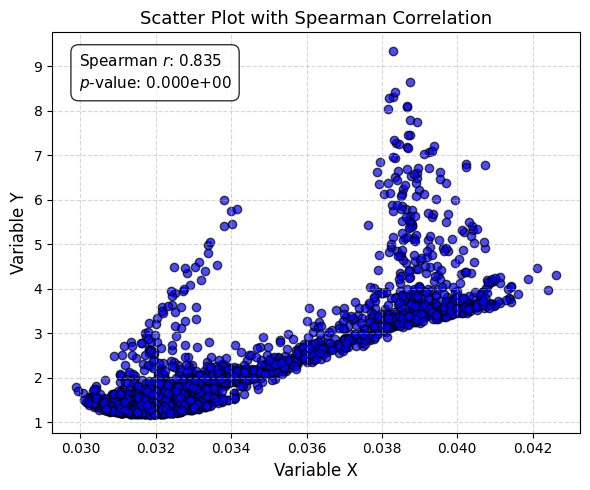

In [474]:
spearman_r, p_value = scipy.stats.spearmanr(g, loc_density)

# 3. Create the scatter plot
plt.figure(figsize=(6, 5))
plt.scatter(g, loc_density, color='blue', alpha=0.7, edgecolors='k', label='Data points')

# 4. Display the Spearman r on the plot
# Placing the text dynamically in the upper left corner of the axes
text_str = f"Spearman $r$: {spearman_r:.3f}\n$p$-value: {p_value:.3e}"
plt.gca().text(0.05, 0.95, text_str, transform=plt.gca().transAxes,
            fontsize=11, verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8))

# 5. Add labels and layout adjustments
plt.xlabel('Variable X', fontsize=12)
plt.ylabel('Variable Y', fontsize=12)
plt.title('Scatter Plot with Spearman Correlation', fontsize=13)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

<Axes: >

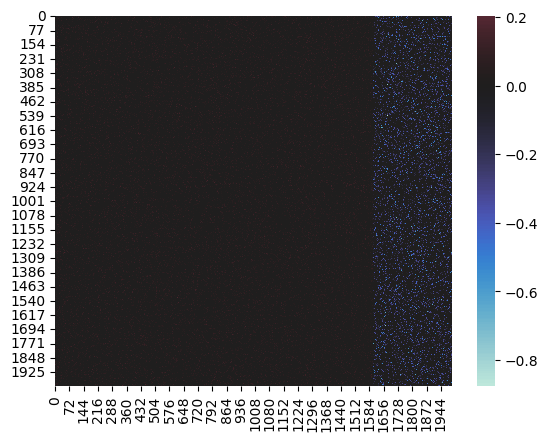

In [351]:
plt.figure()
sns.heatmap(model.W.detach().numpy(),center=0)

In [271]:
4000*.2

800.0

In [272]:
model.N_i

800

In [397]:
import pandas as pd
from tqdm.auto import tqdm
from itertools import product

def run_simulation_and_get_correlation(N, K, beta, dist_std, g_inhib, n_conds=4, steps=400, dt_val=0.01):
    model = SparseBalancedNetwork(
        N=N,
        K=K,
        beta=beta,
        dist_type='uniform',
        dist_mean=1.0,
        dist_std=dist_std,
        g=g_inhib
    )
    
    inputs = torch.zeros(n_conds, N)
    inputs[0, :] = 2
    inputs[1, :] = 5
    inputs[2, :] = 1
    inputs[3, :] = 7
    
    with torch.no_grad():
        R, _, _ = model(I_conditions=inputs, stim_on=100, stim_off=250, dt=dt_val, n_steps=steps)
    
    y = R.cpu().numpy()
    g_msd = get_msd(y.reshape(-1, y.shape[2]).T)
    
    y_norm = (y - np.mean(y, axis=(0, 1), keepdims=True)) / (np.std(y, axis=(0, 1), keepdims=True) + 1e-8)
    y_flat = y_norm.reshape(-1, y_norm.shape[2]).T
    
    loc_density = get_density(y_flat, k=min(500, y_flat.shape[0]-1)).numpy()
    
    spearman_r, _ = scipy.stats.spearmanr(g_msd, loc_density)
    return spearman_r

# Define grid
K_vals = [200, 400, 800]
beta_vals = [0.5, 1.0, 2.0]
dist_std_vals = [0.1, 0.2, 0.5]
g_inhib_vals = [3.0, 4.5, 6.0]

results = []
N_neurons = 1000 # Using 1000 for faster grid search

for K, beta, d_std, g_i in tqdm(product(K_vals, beta_vals, dist_std_vals, g_inhib_vals), total=len(K_vals)*len(beta_vals)*len(dist_std_vals)*len(g_inhib_vals)):
    try:
        corr = run_simulation_and_get_correlation(N_neurons, K, beta, d_std, g_i)
        results.append({
            'K': K,
            'beta': beta,
            'dist_std': d_std,
            'g_inhib': g_i,
            'correlation': corr
        })
    except Exception as e:
        print(f"Error for K={K}, beta={beta}, dist_std={d_std}, g_i={g_i}: {e}")

df_results = pd.DataFrame(results)
best_result = df_results.loc[df_results['correlation'].idxmax()]
print("Best Result:")
print(best_result)


  0%|          | 0/81 [00:00<?, ?it/s]

Best Result:
K              200.000000
beta             0.500000
dist_std         0.200000
g_inhib          4.500000
correlation      0.902997
Name: 4, dtype: float64
